# Kidney dd-cfDNA: combined rules and diagnostic tradeoffs

This notebook reconstructs diagnostic error counts from the published aggregate statistics of [Nie et al. (2025)](https://doi.org/10.3390/diagnostics15030237). It compares fraction alone, absolute concentration alone, either positive (OR), and both positive (AND) in the same 50-recipient biopsy cohort.

**Question:** Compared with fraction alone, what changes when both fractional and absolute dd-cfDNA must be positive?

This educational project accompanies a narrative review on fractional and absolute dd-cfDNA interpretation in kidney transplantation. Original experimental measurements belong to the cited investigators; this secondary analysis does not supply patient records or independent clinical validation.

The original study estimated donor fraction with a 441-SNP sequencing assay and total cfDNA with qPCR. Absolute dd-cfDNA was calculated as total cfDNA multiplied by donor fraction (as a proportion). Fraction can change with recipient-derived cfDNA in its denominator, but discordance alone does not establish a cause.

Run the cells in order to explore the source summaries, count reconstruction, and figures. The notebook includes the aggregate source inputs and analysis code; pandas, NumPy, and matplotlib are required.


In [1]:
from pathlib import Path
import base64, hashlib, importlib.util, json, sys
import pandas as pd
import numpy as np
import matplotlib
from IPython.display import display, Image, FileLink

# Embedded source materials are aggregate summaries, not patient records.
PAYLOAD = {'data/SOURCES.md': 'IyBTb3VyY2UgZGF0YSwgbGljZW5zaW5nLCBhbmQgdHJhbnNmb3JtYXRpb25zCgojIyBQcmltYXJ5IGV2aWRlbmNlCgpOaWUgVywgV2FuZyBZLCBGdSBRLCBldCBhbC4gSW50ZWdyYXRpbmcgRG9ub3IgRGVyaXZlZCBDZWxsLUZyZWUgRE5BIEZyYWN0aW9uIGFuZCBBYnNvbHV0ZSBRdWFudGlmaWNhdGlvbiBmb3IgRW5oYW5jZWQgUmVqZWN0aW9uIERpYWdub3NpcyBpbiBLaWRuZXkgVHJhbnNwbGFudCBSZWNpcGllbnRzLiAqRGlhZ25vc3RpY3MqLiAyMDI1OzE1KDMpOjIzNy4gUHVibGlzaGVkIDIxIEphbnVhcnkgMjAyNS4gRE9JOiBbMTAuMzM5MC9kaWFnbm9zdGljczE1MDMwMjM3XShodHRwczovL2RvaS5vcmcvMTAuMzM5MC9kaWFnbm9zdGljczE1MDMwMjM3KS4gUE1JRDogMzk5NDExNjcuIFBNQ0lEOiBQTUMxMTgxNzQ5OS4KCi0gW1ByaW1hcnkgZnVsbCB0ZXh0XShodHRwczovL3BtYy5uY2JpLm5sbS5uaWguZ292L2FydGljbGVzL1BNQzExODE3NDk5Lykg4oCUIG1ldGhvZHMsIFRhYmxlcyAx4oCTMywgcnVsZSBkZWZpbml0aW9ucywgYW5kIGxpY2Vuc2luZy4KLSBbVGFibGUgMV0oaHR0cHM6Ly9wbWMubmNiaS5ubG0ubmloLmdvdi9hcnRpY2xlcy9QTUMxMTgxNzQ5OS90YWJsZS9kaWFnbm9zdGljcy0xNS0wMDIzNy10MDAxLyk6IDE1IHJlamVjdGlvbiBhbmQgMzUgY29tcGFyYXRvciByZWNpcGllbnRzLgotIFtUYWJsZSAyXShodHRwczovL3BtYy5uY2JpLm5sbS5uaWguZ292L2FydGljbGVzL1BNQzExODE3NDk5L3RhYmxlL2RpYWdub3N0aWNzLTE1LTAwMjM3LXQwMDIvKTogc2l4IGJpb3BzeSBwaGVub3R5cGUgc3VtbWFyaWVzLCBpbmNsdWRpbmcgQUJNUi9taXhlZCwgVENNUiwgYm9yZGVybGluZSBUQ01SLCBCS1ZOLCBJZ0FOL0ZTR1MsIGFuZCBvdGhlci4KLSBbVGFibGUgM10oaHR0cHM6Ly9wbWMubmNiaS5ubG0ubmloLmdvdi9hcnRpY2xlcy9QTUMxMTgxNzQ5OS90YWJsZS9kaWFnbm9zdGljcy0xNS0wMDIzNy10MDAzLyk6IGZvdXIgZGlhZ25vc3RpYyBydWxlcyBhbmQgcmVwb3J0ZWQgc2Vuc2l0aXZpdHksIHNwZWNpZmljaXR5LCBQUFYsIE5QVi4KLSBNZXRob2RzIDIuMiBhbmQgMi404oCTMi42OiBiaW9wc3kgY2xhc3NpZmljYXRpb25zLCB0b3RhbC1jZkROQSBxUENSLCB0YXJnZXRlZCBTTlAgc2VxdWVuY2luZywgYW5kIGNhbGN1bGF0aW9uIG9mIGFic29sdXRlIGRkLWNmRE5BIGZyb20gdG90YWwgY2ZETkEgYW5kIGZyYWN0aW9uLiBGaWd1cmUgMiBjYXB0aW9uOiBjdXRvZmZzIHNlbGVjdGVkIGJ5IG1heGltdW0gWW91ZGVuIGluZGV4LiBTZWN0aW9uIDMuNDogY29tYmluZWQgcnVsZSBkZWZpbml0aW9ucy4KClRoZSBzdHVkeSByZWNydWl0ZWQgYXQgb25lIGNlbnRlciBmcm9tIERlY2VtYmVyIDIwMTkgdG8gQXByaWwgMjAyMS4gUmVqZWN0aW9uIGNvbXByaXNlcyBBQk1SLCBtaXhlZCByZWplY3Rpb24sIGFuZCBUQ01SOyBib3JkZXJsaW5lIFRDTVIgaXMgaW4gaXRzIGNvbXBhcmF0b3IgZ3JvdXAuIEFsbCBmb3VyIHJ1bGVzIHNoYXJlIHRoaXMgY29ob3J0LiBXZSByZXRhaW4gdGhlIHN0dWR5IGRlZmluaXRpb25zIHdpdGhvdXQgaW1wbHlpbmcgdGhhdCBjb21wYXJhdG9ycyBoYXZlIG5vIGluanVyeS4KCiMjIEluY2x1ZGVkIGZpbGVzCgp8IEZpbGUgfCBPYnNlcnZhdGlvbiB1bml0IHwgVHJhbnNmb3JtYXRpb24gfAp8LS0tfC0tLXwtLS18CnwgYHB1Ymxpc2hlZF9zdW1tYXJ5L2RpYWdub3N0aWNfcGVyZm9ybWFuY2UuY3N2YCB8IE9uZSBkaWFnbm9zdGljIHJ1bGUgaW4gdGhlIHNhbWUgY29ob3J0IHwgVGFibGUgMyB0cmFuc2NyaWJlZDsgVGFibGUgMSBkZW5vbWluYXRvcnMgYW5kIHNvdXJjZSBsYWJlbHMgYWRkZWQgfAp8IGBwdWJsaXNoZWRfc3VtbWFyeS9iaW9wc3lfcGhlbm90eXBlX3N1bW1hcmllcy5jc3ZgIHwgT25lIGJpb3BzeSBwaGVub3R5cGUgZ3JvdXAgfCBUYWJsZSAyIHRyYW5zY3JpYmVkOyB1bnJlcG9ydGVkIHF1YXJ0aWxlcyBibGFuayB8CnwgYHByb2Nlc3NlZC9yZWNvbnN0cnVjdGVkX2NvdW50cy5jc3ZgIHwgT25lIHJ1bGUgaW4gdGhlIHNhbWUgY29ob3J0IHwgVFAvVE4gdW5pcXVlbHkgcmVjb25zdHJ1Y3RlZCBmcm9tIHJvdW5kZWQgc2Vuc2l0aXZpdHkvc3BlY2lmaWNpdHk7IEZOL0ZQIGJ5IHN1YnRyYWN0aW9uOyBhbGwgZm91ciByYXRlcyByZWNhbGN1bGF0ZWQgfAp8IGBwcm9jZXNzZWQvcmF0ZV9jaGVja3MuY3N2YCB8IE9uZSBydWxlLW1ldHJpYyBjb21wYXJpc29uIHwgUHVibGlzaGVkIHZlcnN1cyByZWNhbGN1bGF0ZWQgcmF0ZXMgYW5kIHBlcmNlbnRhZ2UtcG9pbnQgZGlmZmVyZW5jZSB8CnwgYHByb2Nlc3NlZC9yb3VuZGluZ19zZW5zaXRpdml0eS5jc3ZgIHwgT25lIHJvdW5kaW5nLXRvbGVyYW5jZSBjaG9pY2UgfCBSZWNvbnN0cnVjdCBhbGwgcnVsZXMgYXQgZWFjaCB0b2xlcmFuY2UgYW5kIGNvbXBhcmUgd2l0aCBiYXNlbGluZSB8CnwgYHByb2Nlc3NlZC9xdWFsaXR5X3JlcG9ydC5qc29uYCB8IFByb2plY3QtbGV2ZWwgc3VtbWFyeSB8IERpbWVuc2lvbnMsIGV4Y2x1c2lvbnMsIGR1cGxpY2F0ZXMsIG1pc3NpbmduZXNzLCBhbmQgY29ob3J0IGNvdW50cyB8CnwgYHByb2Nlc3NlZC9lbnZpcm9ubWVudC5qc29uYCB8IEV4ZWN1dGlvbiBlbnZpcm9ubWVudCB8IEFjdHVhbCBQeXRob24gYW5kIGFuYWx5c2lzLXBhY2thZ2UgdmVyc2lvbnMgfAoKVGhlIHR3byBDU1YgaW5wdXRzIHByZXNlcnZlIHRoZSBwdWJsaXNoZWQtc3VtbWFyeSB0cmFuc2NyaXB0aW9uLiBgSU5QVVRfTUFOSUZFU1QuanNvbmAgcHJlc2VydmVzIHRoZWlyIG9yaWdpbmFsIGJ5dGUgY291bnRzIGFuZCBTSEEtMjU2IGNoZWNrc3Vtcy4gVGhlIGFuYWx5c2lzIHZlcmlmaWVzIGNoZWNrc3VtcyBiZWZvcmUgY2FsY3VsYXRpb247IG5vIHJlbW90ZSBkb3dubG9hZCBpcyBuZWVkZWQuIFRoZSBub3RlYm9vayBlbWJlZHMgdGhlc2UgZXhhY3QgYnl0ZXMgZm9yIHN0YW5kYWxvbmUgZXhlY3V0aW9uLiBgLmdpdGF0dHJpYnV0ZXNgIHByZXZlbnRzIGlucHV0IENTViBsaW5lLWVuZGluZyBub3JtYWxpemF0aW9uIGJ5IEdpdC4KCiMjIyBSdWxlIGxhYmVscwoKLSBGcmFjdGlvbiBhbG9uZSBhbmQgYWJzb2x1dGUgYWxvbmUgcmV0YWluIFRhYmxlIDMgdmFsdWVzIGF0IGN1dG9mZnMgMS4wOCUgYW5kIDMyIGNvcGllcy9tTC4KLSBUYWJsZSAzIOKAnERvdWJsZS1wb3NpdGl2ZeKAnSBiZWNvbWVzICoqQm90aCBwb3NpdGl2ZSAoQU5EKSoqLgotIFRhYmxlIDMg4oCcRG91YmxlLW5lZ2F0aXZl4oCdIG1lYW5zIGJvdGggbWVhc3VyZW1lbnRzIG5lZ2F0aXZlIHRvIGNhbGwgYSBuZWdhdGl2ZSByZXN1bHQsIGhlbmNlICoqRWl0aGVyIHBvc2l0aXZlIChPUikqKiBpcyB0aGUgcG9zaXRpdmUgcnVsZS4KLSBUaGUgcHJvamVjdCByZXByb2R1Y2VzIHJlcG9ydGVkIGFnZ3JlZ2F0ZSBjbGFzc2lmaWNhdGlvbnMuIEl0IGRvZXMgbm90IHJlc29sdmUgYmVoYXZpb3IgZXhhY3RseSBhdCBhIHRocmVzaG9sZCBmcm9tIHBhdGllbnQtbGV2ZWwgcmVjb3JkcywgY2hhbmdlIHBvc2l0aXZpdHkgY29udmVudGlvbnMsIG9yIHJlZml0IGN1dG9mZnMuCgojIyBSZXVzZQoKVGhlIGFydGljbGUgaWRlbnRpZmllcyBpdHMgbGljZW5zZSBhcyBbQ3JlYXRpdmUgQ29tbW9ucyBBdHRyaWJ1dGlvbiA0LjAgSW50ZXJuYXRpb25hbF0oaHR0cHM6Ly9jcmVhdGl2ZWNvbW1vbnMub3JnL2xpY2Vuc2VzL2J5LzQuMC8pLiBPcmlnaW5hbCBhcnRpY2xlIGF1dGhvcnMgcmV0YWluIGNyZWRpdCBmb3IgbWVhc3VyZW1lbnRzIGFuZCBzb3VyY2UgdGFibGVzLiBUcmFuc2NyaWJlZCBhbmQgZGVyaXZlZCB0YWJsZXMgYW5kIHNvdXJjZS1kZXJpdmVkIGZpZ3VyZSBjb250ZW50IGFyZSBzaGFyZWQgdW5kZXIgdGhlIHNhbWUgQ0MgQlkgNC4wIGF0dHJpYnV0aW9uLCB3aXRoIGNoYW5nZXMgZGVzY3JpYmVkIGFib3ZlLiBNSVQgbGljZW5zaW5nIG9mIG9yaWdpbmFsIHByb2plY3QgY29kZSBkb2VzIG5vdCByZWxpY2Vuc2UgdGhpcmQtcGFydHkgbWF0ZXJpYWwuCgpUaGUgcGFwZXIgc3RhdGVzIHRoYXQgaW5kaXZpZHVhbCBkYXRhIGFyZSBhdmFpbGFibGUgb25seSBvbiByZXF1ZXN0IHdpdGggYXBwcm9wcmlhdGUgYXV0aG9yaXphdGlvbiBiZWNhdXNlIG9mIHByaXZhY3kgYW5kIGV0aGljcyByZXN0cmljdGlvbnMuIE5vIGluZGl2aWR1YWwgcmVjb3JkcywgaWRlbnRpdGllcywgdW5wdWJsaXNoZWQgbWFudXNjcmlwdCwgb3IgaW5mZXJyZWQgcGF0aWVudCBkaXN0cmlidXRpb25zIGFyZSBzdXBwbGllZCBoZXJlLiBUaGlzIGlzIG5vdCBhIHN5c3RlbWF0aWMgcmV2aWV3IG9yIG1ldGEtYW5hbHlzaXMuIE5vIG5ldyBsaXRlcmF0dXJlIHNlYXJjaCBiZXlvbmQgc291cmNlIHZlcmlmaWNhdGlvbiBpcyByZXByZXNlbnRlZCBhcyBleGhhdXN0aXZlLgo=', 'NOTICE.md': 'IyBUaGlyZC1wYXJ0eSBhdHRyaWJ1dGlvbgoKT3JpZ2luYWwgc3R1ZHkgYW5kIHNvdXJjZSB0YWJsZXM6IE5pZSBXLCBXYW5nIFksIEZ1IFEsIGV0IGFsLiAqSW50ZWdyYXRpbmcgRG9ub3IgRGVyaXZlZCBDZWxsLUZyZWUgRE5BIEZyYWN0aW9uIGFuZCBBYnNvbHV0ZSBRdWFudGlmaWNhdGlvbiBmb3IgRW5oYW5jZWQgUmVqZWN0aW9uIERpYWdub3NpcyBpbiBLaWRuZXkgVHJhbnNwbGFudCBSZWNpcGllbnRzKi4gRGlhZ25vc3RpY3MuIDIwMjU7MTUoMyk6MjM3LiBodHRwczovL2RvaS5vcmcvMTAuMzM5MC9kaWFnbm9zdGljczE1MDMwMjM3CgpDb3B5cmlnaHQgMjAyNSBieSB0aGUgYXJ0aWNsZSBhdXRob3JzLiBbQ0MgQlkgNC4wXShodHRwczovL2NyZWF0aXZlY29tbW9ucy5vcmcvbGljZW5zZXMvYnkvNC4wLykuIFNvdXJjZSB0YWJsZXMgd2VyZSB0cmFuc2NyaWJlZCBpbnRvIENTVjsgYWdncmVnYXRlIGNvdW50cyB3ZXJlIHJlY29uc3RydWN0ZWQ7IHJhdGVzIHdlcmUgcmVjYWxjdWxhdGVkOyBuZXcgZmlndXJlcyBhbmQgYW4gZWR1Y2F0aW9uYWwgZ3VpZGUgd2VyZSBnZW5lcmF0ZWQuIE5vIGVuZG9yc2VtZW50IGJ5IHRoZSBvcmlnaW5hbCBhdXRob3JzIGlzIGltcGxpZWQuIFNvdXJjZS1kZXJpdmVkIHRhYmxlcyBhbmQgZmlndXJlIGNvbnRlbnQgcmV0YWluIENDIEJZIDQuMCBhdHRyaWJ1dGlvbi4gU2VlIGRhdGEvU09VUkNFUy5tZCBmb3IgZXhhY3QgdGFibGUgbG9jYXRvcnMgYW5kIHRyYW5zZm9ybWF0aW9ucy4K', 'LICENSE': 'TUlUIExpY2Vuc2UKCkNvcHlyaWdodCAoYykgMjAyNiBLaWRuZXkgZGQtY2ZETkEgZGVjaXNpb24gdHJhZGVvZmZzIHByb2plY3QgY29udHJpYnV0b3JzCgpQZXJtaXNzaW9uIGlzIGhlcmVieSBncmFudGVkLCBmcmVlIG9mIGNoYXJnZSwgdG8gYW55IHBlcnNvbiBvYnRhaW5pbmcgYSBjb3B5Cm9mIHRoaXMgc29mdHdhcmUgYW5kIGFzc29jaWF0ZWQgZG9jdW1lbnRhdGlvbiBmaWxlcyAodGhlICJTb2Z0d2FyZSIpLCB0byBkZWFsCmluIHRoZSBTb2Z0d2FyZSB3aXRob3V0IHJlc3RyaWN0aW9uLCBpbmNsdWRpbmcgd2l0aG91dCBsaW1pdGF0aW9uIHRoZSByaWdodHMKdG8gdXNlLCBjb3B5LCBtb2RpZnksIG1lcmdlLCBwdWJsaXNoLCBkaXN0cmlidXRlLCBzdWJsaWNlbnNlLCBhbmQvb3Igc2VsbApjb3BpZXMgb2YgdGhlIFNvZnR3YXJlLCBhbmQgdG8gcGVybWl0IHBlcnNvbnMgdG8gd2hvbSB0aGUgU29mdHdhcmUgaXMKZnVybmlzaGVkIHRvIGRvIHNvLCBzdWJqZWN0IHRvIHRoZSBmb2xsb3dpbmcgY29uZGl0aW9uczoKClRoZSBhYm92ZSBjb3B5cmlnaHQgbm90aWNlIGFuZCB0aGlzIHBlcm1pc3Npb24gbm90aWNlIHNoYWxsIGJlIGluY2x1ZGVkIGluIGFsbApjb3BpZXMgb3Igc3Vic3RhbnRpYWwgcG9ydGlvbnMgb2YgdGhlIFNvZnR3YXJlLgoKVEhFIFNPRlRXQVJFIElTIFBST1ZJREVEICJBUyBJUyIsIFdJVEhPVVQgV0FSUkFOVFkgT0YgQU5ZIEtJTkQsIEVYUFJFU1MgT1IKSU1QTElFRCwgSU5DTFVESU5HIEJVVCBOT1QgTElNSVRFRCBUTyBUSEUgV0FSUkFOVElFUyBPRiBNRVJDSEFOVEFCSUxJVFksCkZJVE5FU1MgRk9SIEEgUEFSVElDVUxBUiBQVVJQT1NFIEFORCBOT05JTkZSSU5HRU1FTlQuIElOIE5PIEVWRU5UIFNIQUxMIFRIRQpBVVRIT1JTIE9SIENPUFlSSUdIVCBIT0xERVJTIEJFIExJQUJMRSBGT1IgQU5ZIENMQUlNLCBEQU1BR0VTIE9SIE9USEVSCkxJQUJJTElUWSwgV0hFVEhFUiBJTiBBTiBBQ1RJT04gT0YgQ09OVFJBQ1QsIFRPUlQgT1IgT1RIRVJXSVNFLCBBUklTSU5HIEZST00sCk9VVCBPRiBPUiBJTiBDT05ORUNUSU9OIFdJVEggVEhFIFNPRlRXQVJFIE9SIFRIRSBVU0UgT1IgT1RIRVIgREVBTElOR1MgSU4gVEhFClNPRlRXQVJFLgoKU2NvcGU6IG9yaWdpbmFsIHByb2plY3QgY29kZSBhbmQgb3JpZ2luYWwgZG9jdW1lbnRhdGlvbiBvbmx5LiBUaGlyZC1wYXJ0eQphcnRpY2xlIGNvbnRlbnQgYW5kIHRyYW5zY3JpYmVkL2FkYXB0ZWQgdGFibGVzIHJldGFpbiB0aGUgYXJ0aWNsZSdzIENDIEJZIDQuMApsaWNlbnNlIGFuZCBhdHRyaWJ1dGlvbiByZXF1aXJlbWVudHM7IHNlZSBkYXRhL1NPVVJDRVMubWQgYW5kIE5PVElDRS5tZC4K', 'run_analysis.py': 'IiIiUHVibGlzaGVkIGFnZ3JlZ2F0ZSByZWFuYWx5c2lzIG9mIE5pZSBldCBhbC4gMjAyNSwgRE9JIDEwLjMzOTAvZGlhZ25vc3RpY3MxNTAzMDIzNy4iIiIKZnJvbSBwYXRobGliIGltcG9ydCBQYXRoCmZyb20gZGVjaW1hbCBpbXBvcnQgRGVjaW1hbAppbXBvcnQgaGFzaGxpYiwganNvbiwgcGxhdGZvcm0KaW1wb3J0IG1hdHBsb3RsaWIKbWF0cGxvdGxpYi51c2UoJ0FnZycpCmltcG9ydCBtYXRwbG90bGliLnB5cGxvdCBhcyBwbHQKaW1wb3J0IHBhbmRhcyBhcyBwZAppbXBvcnQgbnVtcHkgYXMgbnAKUk9PVD1QYXRoKF9fZmlsZV9fKS5yZXNvbHZlKCkucGFyZW50ClJVTEVTPVsnRnJhY3Rpb24gYWxvbmUnLCdBYnNvbHV0ZSBhbG9uZScsJ0VpdGhlciBwb3NpdGl2ZSAoT1IpJywnQm90aCBwb3NpdGl2ZSAoQU5EKSddCk1FVFJJQ1M9WydzZW5zaXRpdml0eScsJ3NwZWNpZmljaXR5JywncHB2JywnbnB2J10KCmRlZiB1bmlxdWVfY291bnQocmF0ZSxuLHRvbGVyYW5jZT0nMC4wMDUnKToKICAgICIiIkVudW1lcmF0ZSBhbGwgaW50ZWdlciBudW1lcmF0b3JzIGNvbXBhdGlibGUgd2l0aCByb3VuZGVkIHBlcmNlbnRhZ2VzOyBmYWlsIGNsb3NlZC4iIiIKICAgIGlmIG48MSBvciBpbnQobikhPW46IHJhaXNlIFZhbHVlRXJyb3IoJ0ludmFsaWQgZGVub21pbmF0b3InKQogICAgdGFyZ2V0LHRvbD1EZWNpbWFsKHN0cihyYXRlKSksRGVjaW1hbChzdHIodG9sZXJhbmNlKSkKICAgIGlmIG5vdCAwPD10YXJnZXQ8PTEwMCBvciB0b2w8MDogcmFpc2UgVmFsdWVFcnJvcignSW52YWxpZCByYXRlIG9yIHRvbGVyYW5jZScpCiAgICBtYXRjaGVzPVtrIGZvciBrIGluIHJhbmdlKGludChuKSsxKSBpZiBhYnMoRGVjaW1hbCgxMDApKmsvaW50KG4pLXRhcmdldCk8PXRvbF0KICAgIGlmIGxlbihtYXRjaGVzKSE9MTogcmFpc2UgVmFsdWVFcnJvcihmJ05vbnVuaXF1ZS9pbXBvc3NpYmxlIGNvdW50OiB7bWF0Y2hlc30nKQogICAgcmV0dXJuIG1hdGNoZXNbMF0KCmRlZiBsb2FkX2lucHV0cyhyb290PVJPT1QpOgogICAgZm9yIGVudHJ5IGluIGpzb24ubG9hZHMoKHJvb3QvJ0lOUFVUX01BTklGRVNULmpzb24nKS5yZWFkX3RleHQoKSlbJ2ZpbGVzJ106CiAgICAgICAgaWYgaGFzaGxpYi5zaGEyNTYoKHJvb3QvZW50cnlbJ3BhdGgnXSkucmVhZF9ieXRlcygpKS5oZXhkaWdlc3QoKSE9ZW50cnlbJ3NoYTI1NiddOgogICAgICAgICAgICByYWlzZSBWYWx1ZUVycm9yKCdJbnB1dCBjaGVja3N1bSBtaXNtYXRjaDogJytlbnRyeVsncGF0aCddKQogICAgZD1wZC5yZWFkX2Nzdihyb290LydkYXRhL3B1Ymxpc2hlZF9zdW1tYXJ5L2RpYWdub3N0aWNfcGVyZm9ybWFuY2UuY3N2JykKICAgIHA9cGQucmVhZF9jc3Yocm9vdC8nZGF0YS9wdWJsaXNoZWRfc3VtbWFyeS9iaW9wc3lfcGhlbm90eXBlX3N1bW1hcmllcy5jc3YnKQogICAgaWYgZC5ydWxlLnRvbGlzdCgpIT1SVUxFUyBvciBsZW4ocCkhPTY6IHJhaXNlIFZhbHVlRXJyb3IoJ1VuZXhwZWN0ZWQgc291cmNlIHJvd3MnKQogICAgaWYgZC5kdXBsaWNhdGVkKCdydWxlJykuYW55KCkgb3IgcC5kdXBsaWNhdGVkKCdwaGVub3R5cGUnKS5hbnkoKTogcmFpc2UgVmFsdWVFcnJvcignRHVwbGljYXRlIGtleScpCiAgICBpZiBkW1ttKydfcGVyY2VudCcgZm9yIG0gaW4gTUVUUklDU10rWyduX3JlamVjdGlvbicsJ25fbm9ucmVqZWN0aW9uJ11dLmlzbmEoKS5hbnkoKS5hbnkoKToKICAgICAgICByYWlzZSBWYWx1ZUVycm9yKCdNaXNzaW5nIHJhdGUgb3IgZGVub21pbmF0b3InKQogICAgaWYgbm90IGQubl9yZWplY3Rpb24uZXEoMTUpLmFsbCgpIG9yIG5vdCBkLm5fbm9ucmVqZWN0aW9uLmVxKDM1KS5hbGwoKTogcmFpc2UgVmFsdWVFcnJvcignV3JvbmcgZGVub21pbmF0b3JzJykKICAgIGlmIHAubi5zdW0oKSE9NTAgb3IgcC5pbG9jWzoyXS5uLnN1bSgpIT0xNTogcmFpc2UgVmFsdWVFcnJvcignUGhlbm90eXBlIHRvdGFsIG1pc21hdGNoJykKICAgIG1pc3Npbmc9eyhyLnBoZW5vdHlwZSxjKSBmb3IgXyxyIGluIHAuaXRlcnJvd3MoKSBmb3IgYyBpbiBwLmNvbHVtbnMgaWYgcGQuaXNuYShyW2NdKX0KICAgIGV4cGVjdGVkPXsoJ1RDTVInLGMpIGZvciBjIGluIFsnZnJhY3Rpb25fcTFfcGVyY2VudCcsJ2ZyYWN0aW9uX3EzX3BlcmNlbnQnLCdhYnNvbHV0ZV9xMV9jb3BpZXNfbWwnLCdhYnNvbHV0ZV9xM19jb3BpZXNfbWwnXX0KICAgIGlmIG1pc3NpbmchPWV4cGVjdGVkOiByYWlzZSBWYWx1ZUVycm9yKCdVbmV4cGVjdGVkIHBoZW5vdHlwZSBtaXNzaW5nbmVzcycpCiAgICBxYz1kaWN0KGlucHV0X3J1bGVfcm93cz00LGluY2x1ZGVkX3J1bGVfcm93cz00LGlucHV0X3BoZW5vdHlwZV9yb3dzPTYsaW5jbHVkZWRfcGhlbm90eXBlX3Jvd3M9NiwKICAgICAgICBleGNsdWRlZF9yb3dzPTAsZHVwbGljYXRlX3J1bGVfa2V5cz1pbnQoZC5kdXBsaWNhdGVkKCdydWxlJykuc3VtKCkpLGR1cGxpY2F0ZV9waGVub3R5cGVfa2V5cz1pbnQocC5kdXBsaWNhdGVkKCdwaGVub3R5cGUnKS5zdW0oKSksCiAgICAgICAgbWlzc2luZ19kaWFnbm9zdGljX2NlbGxzPWludChkLmlzbmEoKS5zdW0oKS5zdW0oKSksbWlzc2luZ19waGVub3R5cGVfY2VsbHM9aW50KHAuaXNuYSgpLnN1bSgpLnN1bSgpKSwKICAgICAgICBtaXNzaW5nbmVzcz0nVHdvIGluYXBwbGljYWJsZSBjdXRvZmZzOyBmb3VyIHVucmVwb3J0ZWQgVENNUiBxdWFydGlsZXMgKG49MSkuIE5vIGltcHV0YXRpb24uJywKICAgICAgICByZWNpcGllbnRzPTUwLHJlamVjdGlvbj0xNSxjb21wYXJhdG9yPTM1LHJlamVjdGlvbl9wcmV2YWxlbmNlX3BlcmNlbnQ9MzAsCiAgICAgICAgdW5pdD0nT25lIHJ1bGUgb3IgcGhlbm90eXBlIHN1bW1hcnksIG5ldmVyIGEgcGF0aWVudCcscGF0aWVudF9sZXZlbF9RQz0nTm90IGFzc2Vzc2FibGUnLHNvdXJjZV9oYXNoZXNfdmVyaWZpZWQ9VHJ1ZSkKICAgIHJldHVybiBkLHAscWMKCmRlZiB2YWxpZGF0ZV9ydWxlX2xvZ2ljKGQpOgogICAgaW5kZXhlZD1kLnNldF9pbmRleCgncnVsZScpCiAgICBmb3IgYyBpbiBbJ1RQJywnRlAnXToKICAgICAgICBmLGEsZSxiPWluZGV4ZWQubG9jW1JVTEVTLGNdLnRvbGlzdCgpCiAgICAgICAgaWYgZSE9ZithLWIgb3Igbm90IDA8PWI8PW1pbihmLGEpIG9yIGU8bWF4KGYsYSk6IHJhaXNlIFZhbHVlRXJyb3IoJ0NvbWJpbmVkIHJ1bGUgaW5jb25zaXN0ZW5jeScpCgpkZWYgcmVjb25zdHJ1Y3QoZCx0b2xlcmFuY2U9JzAuMDA1Jyk6CiAgICByb3dzLGNoZWNrcz1bXSxbXQogICAgZm9yIF8sciBpbiBkLml0ZXJyb3dzKCk6CiAgICAgICAgbixtPWludChyLm5fcmVqZWN0aW9uKSxpbnQoci5uX25vbnJlamVjdGlvbikKICAgICAgICB0cCx0bj11bmlxdWVfY291bnQoci5zZW5zaXRpdml0eV9wZXJjZW50LG4sdG9sZXJhbmNlKSx1bmlxdWVfY291bnQoci5zcGVjaWZpY2l0eV9wZXJjZW50LG0sdG9sZXJhbmNlKQogICAgICAgIGZuLGZwPW4tdHAsbS10bgogICAgICAgIHJhdGVzPWRpY3Qoc2Vuc2l0aXZpdHk9MTAwKnRwL24sc3BlY2lmaWNpdHk9MTAwKnRuL20scHB2PTEwMCp0cC8odHArZnApLG5wdj0xMDAqdG4vKHRuK2ZuKSkKICAgICAgICByb3c9ZGljdChydWxlPXIucnVsZSxUUD10cCxGTj1mbixUTj10bixGUD1mcCxuX3JlamVjdGlvbj1uLG5fbm9ucmVqZWN0aW9uPW0scHJvdmVuYW5jZT0ncmVjb25zdHJ1Y3RlZCBmcm9tIHB1Ymxpc2hlZCBzdW1tYXJpZXMnLHNvdXJjZV9kb2k9JzEwLjMzOTAvZGlhZ25vc3RpY3MxNTAzMDIzNycsc291cmNlX3RhYmxlPSdUYWJsZSAzOyBkZW5vbWluYXRvcnMgVGFibGUgMScpCiAgICAgICAgZm9yIG1ldHJpYyx2YWx1ZSBpbiByYXRlcy5pdGVtcygpOgogICAgICAgICAgICByZXBvcnRlZD1mbG9hdChyW21ldHJpYysnX3BlcmNlbnQnXSk7IGRlbHRhPXZhbHVlLXJlcG9ydGVkOyBtYXRjaD1hYnMoZGVsdGEpPD0wLjAwNSsxZS0xMAogICAgICAgICAgICBjaGVja3MuYXBwZW5kKGRpY3QocnVsZT1yLnJ1bGUsbWV0cmljPW1ldHJpYyxyZXBvcnRlZF9wZXJjZW50PXJlcG9ydGVkLHJlY2FsY3VsYXRlZF9wZXJjZW50PXZhbHVlLGRpZmZlcmVuY2VfcGVyY2VudGFnZV9wb2ludHM9ZGVsdGEsbWF0Y2hlc19yb3VuZGluZz1tYXRjaCkpCiAgICAgICAgICAgIGlmIG5vdCBtYXRjaDogcmFpc2UgVmFsdWVFcnJvcihmJ3ttZXRyaWN9IGRpc2NyZXBhbmN5IGZvciB7ci5ydWxlfScpCiAgICAgICAgICAgIHJvd1ttZXRyaWMrJ19wZXJjZW50J109dmFsdWUKICAgICAgICByb3dzLmFwcGVuZChyb3cpCiAgICBkZXJpdmVkPXBkLkRhdGFGcmFtZShyb3dzKTsgdmFsaWRhdGVfcnVsZV9sb2dpYyhkZXJpdmVkKQogICAgcmV0dXJuIGRlcml2ZWQscGQuRGF0YUZyYW1lKGNoZWNrcykKCmRlZiByb3VuZGluZ19zZW5zaXRpdml0eShkKToKICAgIGJhc2VsaW5lLF89cmVjb25zdHJ1Y3QoZCk7IHJvd3M9W10KICAgIGZvciB0b2xlcmFuY2UgaW4gWycwLjAwNScsJzAuMDEnLCcwLjA1J106CiAgICAgICAgY2FuZGlkYXRlLF89cmVjb25zdHJ1Y3QoZCx0b2xlcmFuY2UpCiAgICAgICAgc3RhYmxlPWNhbmRpZGF0ZVtbJ1RQJywnRk4nLCdUTicsJ0ZQJ11dLmVxdWFscyhiYXNlbGluZVtbJ1RQJywnRk4nLCdUTicsJ0ZQJ11dKQogICAgICAgIGlmIG5vdCBzdGFibGU6IHJhaXNlIFZhbHVlRXJyb3IoJ1JvdW5kaW5nIHNlbnNpdGl2aXR5IGNoYW5nZWQgY291bnRzJykKICAgICAgICByb3dzLmFwcGVuZChkaWN0KHRvbGVyYW5jZV9wZXJjZW50YWdlX3BvaW50cz1mbG9hdCh0b2xlcmFuY2UpLHVuaXF1ZV9jb3VudHNfdW5jaGFuZ2VkPXN0YWJsZSkpCiAgICByZXR1cm4gcGQuRGF0YUZyYW1lKHJvd3MpCgpkZWYgZXhwb3J0X2ZpZ3VyZXMoZCxyb290PVJPT1QpOgogICAgb3V0PXJvb3QvJ2ZpZ3VyZXMnOyBvdXQubWtkaXIocGFyZW50cz1UcnVlLGV4aXN0X29rPVRydWUpCiAgICBwbHQucmNQYXJhbXMudXBkYXRlKHsnZm9udC5mYW1pbHknOidEZWphVnUgU2FucycsJ2ZvbnQuc2l6ZSc6MTEsJ2F4ZXMuc3BpbmVzLnRvcCc6RmFsc2UsJ2F4ZXMuc3BpbmVzLnJpZ2h0JzpGYWxzZSwnYXhlcy5zcGluZXMubGVmdCc6RmFsc2UsJ2F4ZXMuYXhpc2JlbG93JzpUcnVlLCdzYXZlZmlnLmZhY2Vjb2xvcic6J3doaXRlJ30pCiAgICBsYWJlbHM9WydGcmFjdGlvblxuYWxvbmUnLCdBYnNvbHV0ZVxuYWxvbmUnLCdFaXRoZXIgcG9zaXRpdmVcbk9SJywnQm90aCBwb3NpdGl2ZVxuQU5EJ107IHg9bnAuYXJhbmdlKDQpCiAgICBmaWcsYXg9cGx0LnN1YnBsb3RzKGZpZ3NpemU9KDEwLDYpKQogICAgZm9yIHNoaWZ0LGtleSxjb2xvcixsYWJlbCBpbiBbKC0uMTksJ3NlbnNpdGl2aXR5JywnIzE3NmI4NycsJ1NlbnNpdGl2aXR5OiByZWplY3Rpb24gbj0xNScpLCguMTksJ3NwZWNpZmljaXR5JywnI2QwN2EyOScsJ1NwZWNpZmljaXR5OiBjb21wYXJhdG9yIG49MzUnKV06CiAgICAgICAgYmFycz1heC5iYXIoeCtzaGlmdCxkW2tleSsnX3BlcmNlbnQnXSx3aWR0aD0uMzQsY29sb3I9Y29sb3IsbGFiZWw9bGFiZWwpCiAgICAgICAgYXguYmFyX2xhYmVsKGJhcnMsbGFiZWxzPVtmJ3t2Oi4yZn0lJyBmb3IgdiBpbiBkW2tleSsnX3BlcmNlbnQnXV0scGFkZGluZz00LGZvbnRzaXplPTEwKQogICAgYXguc2V0KHh0aWNrcz14LHh0aWNrbGFiZWxzPWxhYmVscyx5bGltPSgwLDExNikseXRpY2tzPW5wLmFyYW5nZSgwLDEwMSwyMCkseWxhYmVsPSdEaWFnbm9zdGljIHJhdGUgKCUpJyx0aXRsZT0nQ29tYmluZWQgcG9zaXRpdml0eSBjaGFuZ2VzIHRoZSB0cmFkZW9mZicpCiAgICBheC5ncmlkKGF4aXM9J3knLGFscGhhPS4xOCk7IGF4LmxlZ2VuZChsb2M9J3VwcGVyIGNlbnRlcicsYmJveF90b19hbmNob3I9KC41LC0uMTMpLG5jb2w9MixmcmFtZW9uPUZhbHNlLGZvbnRzaXplPTEwKQogICAgZmlnLnRleHQoLjA3NSwuMDI1LCdOaWUgZXQgYWwuICgyMDI1KSwgVGFibGUgMy4gU2FtZSA1MC1yZWNpcGllbnQgY29ob3J0LiBDdXRvZmZzOiAxLjA4JTsgMzIgY29waWVzL21MLlxuUmF0ZXMgcmVwcm9kdWNlZCBmcm9tIHB1Ymxpc2hlZCBzdW1tYXJpZXM7IGN1dG9mZnMgc2VsZWN0ZWQgaW4gdGhpcyBjb2hvcnQuIE5vIGV4dGVybmFsIHZhbGlkYXRpb24uJyxmb250c2l6ZT05LGNvbG9yPScjNDQ1MTViJykKICAgIGZpZy5zdWJwbG90c19hZGp1c3QoYm90dG9tPS4yNix0b3A9Ljg4LGxlZnQ9LjA5LHJpZ2h0PS45OCk7IGZpZy5zYXZlZmlnKG91dC8nMDFfZGlhZ25vc3RpY19wZXJmb3JtYW5jZS5wbmcnLGRwaT0xODApOyBwbHQuY2xvc2UoZmlnKQogICAgZmlnLGF4ZXM9cGx0LnN1YnBsb3RzKDEsMixmaWdzaXplPSgxMSw1LjcpKQogICAgZm9yIGF4LGMsdGl0bGUsY29sb3IsZGVub21pbmF0b3IsdXBwZXIgaW4gWyhheGVzWzBdLCdGTicsJ01pc3NlZCByZWplY3Rpb25zJywnIzE3NmI4NycsMTUsNSksKGF4ZXNbMV0sJ0ZQJywnRmFsc2UgcG9zaXRpdmVzJywnI2QwN2EyOScsMzUsMTQpXToKICAgICAgICBiYXJzPWF4LmJhcih4LGRbY10sY29sb3I9Y29sb3Isd2lkdGg9LjYyKTsgYXguYmFyX2xhYmVsKGJhcnMsbGFiZWxzPVtmJ3t2fS97ZGVub21pbmF0b3J9JyBmb3IgdiBpbiBkW2NdXSxwYWRkaW5nPTUpCiAgICAgICAgYXguc2V0KHh0aWNrcz14LHh0aWNrbGFiZWxzPWxhYmVscyx5bGltPSgwLHVwcGVyKSx0aXRsZT10aXRsZSx5bGFiZWw9ZidSZWNpcGllbnRzIChvdXQgb2Yge2Rlbm9taW5hdG9yfSknKQogICAgICAgIGF4LnlheGlzLnNldF9tYWpvcl9sb2NhdG9yKHBsdC5NYXhOTG9jYXRvcihpbnRlZ2VyPVRydWUpKTsgYXguZ3JpZChheGlzPSd5JyxhbHBoYT0uMTgpOyBheC50aWNrX3BhcmFtcyhheGlzPSd4JyxsYWJlbHNpemU9OSkKICAgIGZpZy5zdXB0aXRsZSgnQU5EIGF2b2lkcyAyIGZhbHNlIHBvc2l0aXZlcyBidXQgbWlzc2VzIDMgYWRkaXRpb25hbCByZWplY3Rpb25zJyxmb250c2l6ZT0xMykKICAgIGZpZy50ZXh0KC4wNzUsLjAzNSwnUmVsYXRpdmUgdG8gZnJhY3Rpb24gYWxvbmUsIGluIHRoaXMgY29ob3J0IG9ubHkuIENvdW50cyByZWNvbnN0cnVjdGVkIGZyb20gcHVibGlzaGVkIHN1bW1hcmllcy5cblBhbmVscyBoYXZlIGRpZmZlcmVudCBkZW5vbWluYXRvcnMgYW5kIHNjYWxlczsgdGhleSBkbyBub3QgYXNzaWduIGVxdWFsIGNsaW5pY2FsIGNvc3RzLicsZm9udHNpemU9OSxjb2xvcj0nIzQ0NTE1YicpCiAgICBmaWcuc3VicGxvdHNfYWRqdXN0KGJvdHRvbT0uMjIsdG9wPS44MyxsZWZ0PS4wNzUscmlnaHQ9Ljk4LHdzcGFjZT0uMjQpOyBmaWcuc2F2ZWZpZyhvdXQvJzAyX2RpYWdub3N0aWNfZXJyb3JzLnBuZycsZHBpPTE4MCk7IHBsdC5jbG9zZShmaWcpCgpkZWYgc2F2ZV9yZXN1bHRzKGQsY2hlY2tzLHFjLHNlbnNpdGl2aXR5LHJvb3Q9Uk9PVCk6CiAgICBvdXQ9cm9vdC8nZGF0YS9wcm9jZXNzZWQnOyBvdXQubWtkaXIocGFyZW50cz1UcnVlLGV4aXN0X29rPVRydWUpCiAgICBkLnRvX2NzdihvdXQvJ3JlY29uc3RydWN0ZWRfY291bnRzLmNzdicsaW5kZXg9RmFsc2UsZmxvYXRfZm9ybWF0PSclLjhmJykKICAgIGNoZWNrcy50b19jc3Yob3V0LydyYXRlX2NoZWNrcy5jc3YnLGluZGV4PUZhbHNlLGZsb2F0X2Zvcm1hdD0nJS44ZicpCiAgICBzZW5zaXRpdml0eS50b19jc3Yob3V0Lydyb3VuZGluZ19zZW5zaXRpdml0eS5jc3YnLGluZGV4PUZhbHNlKQogICAgKG91dC8ncXVhbGl0eV9yZXBvcnQuanNvbicpLndyaXRlX3RleHQoanNvbi5kdW1wcyhxYyxpbmRlbnQ9MikrJ1xuJykKICAgIGVudj1kaWN0KHB5dGhvbj1wbGF0Zm9ybS5weXRob25fdmVyc2lvbigpLHBhbmRhcz1wZC5fX3ZlcnNpb25fXyxudW1weT1ucC5fX3ZlcnNpb25fXyxtYXRwbG90bGliPW1hdHBsb3RsaWIuX192ZXJzaW9uX18pCiAgICAob3V0LydlbnZpcm9ubWVudC5qc29uJykud3JpdGVfdGV4dChqc29uLmR1bXBzKGVudixpbmRlbnQ9MikrJ1xuJykKICAgIGRvY3M9cm9vdC8nZG9jcyc7IGRvY3MubWtkaXIoZXhpc3Rfb2s9VHJ1ZSkKICAgIChkb2NzLydyZXN1bHRzLmpzJykud3JpdGVfdGV4dCgnd2luZG93LlJFU1VMVFMgPSAnK2QudG9fanNvbihvcmllbnQ9J3JlY29yZHMnLGluZGVudD0yKSsnO1xuJykKCmRlZiBtYWluKHJvb3Q9Uk9PVCk6CiAgICBzb3VyY2UscGhlbm90eXBlLHFjPWxvYWRfaW5wdXRzKHJvb3QpOyBkLGNoZWNrcz1yZWNvbnN0cnVjdChzb3VyY2UpOyBzZW5zaXRpdml0eT1yb3VuZGluZ19zZW5zaXRpdml0eShzb3VyY2UpCiAgICBleHBvcnRfZmlndXJlcyhkLHJvb3QpOyBzYXZlX3Jlc3VsdHMoZCxjaGVja3MscWMsc2Vuc2l0aXZpdHkscm9vdCkKICAgIHByaW50KGRbWydydWxlJywnVFAnLCdGTicsJ1ROJywnRlAnXV0udG9fc3RyaW5nKGluZGV4PUZhbHNlKSkKICAgIHByaW50KGYnXG57bGVuKGNoZWNrcyl9LzE2IHJhdGUgY2hlY2tzIHBhc3MuIEFsbCAzIHJvdW5kaW5nIHRvbGVyYW5jZXMgYWdyZWUuJykKICAgIHByaW50KCdBZ2dyZWdhdGUgcmVjb25zdHJ1Y3Rpb24gb25seTsgbm90IGluZGVwZW5kZW50IGNsaW5pY2FsIHZhbGlkYXRpb24uJykKICAgIHJldHVybiBkCgppZiBfX25hbWVfXz09J19fbWFpbl9fJzogbWFpbigpCg==', 'INPUT_MANIFEST.json': 'ewogICJjaGVja2VkX2RhdGUiOiAiMjAyNi0xMS0wOSIsCiAgImZpbGVzIjogWwogICAgewogICAgICAicGF0aCI6ICJkYXRhL3B1Ymxpc2hlZF9zdW1tYXJ5L2Jpb3BzeV9waGVub3R5cGVfc3VtbWFyaWVzLmNzdiIsCiAgICAgICJieXRlcyI6IDY0MSwKICAgICAgInNoYTI1NiI6ICI2YTYyZjhmMWZkZjUyMTYxNmMxODRhOGExMWUxNjQ0MjI3MzI2YTVkOTAzNGNjZDkwNzNmZTkxZjg3ZWRlYzQ2IiwKICAgICAgInJvbGUiOiAidHJhbnNjcmliZWQgcHVibGlzaGVkIHN1bW1hcnkiCiAgICB9LAogICAgewogICAgICAicGF0aCI6ICJkYXRhL3B1Ymxpc2hlZF9zdW1tYXJ5L2RpYWdub3N0aWNfcGVyZm9ybWFuY2UuY3N2IiwKICAgICAgImJ5dGVzIjogNjk2LAogICAgICAic2hhMjU2IjogIjA0MjY0MzZlNjJlMTRmMTdjY2FmOWQ1NGI2NzkzOGRlNjUyZWY2NzRjNDU0MjZkYTFmOTViYzc0ZGZmNmFmMjIiLAogICAgICAicm9sZSI6ICJ0cmFuc2NyaWJlZCBwdWJsaXNoZWQgc3VtbWFyeSIKICAgIH0KICBdCn0K', 'data/published_summary/diagnostic_performance.csv': 'cnVsZSxzb3VyY2VfbGFiZWwsZnJhY3Rpb25fY3V0b2ZmX3BlcmNlbnQsYWJzb2x1dGVfY3V0b2ZmX2NvcGllc19tbCxzZW5zaXRpdml0eV9wZXJjZW50LHNwZWNpZmljaXR5X3BlcmNlbnQscHB2X3BlcmNlbnQsbnB2X3BlcmNlbnQsbl9yZWplY3Rpb24sbl9ub25yZWplY3Rpb24sc291cmNlX2RvaSxzb3VyY2VfdGFibGUKRnJhY3Rpb24gYWxvbmUsZGQtY2ZETkEgRnJhY3Rpb24sMS4wOCwsOTMuMzMsOTEuNDMsODIuMzUsOTYuOTcsMTUsMzUsMTAuMzM5MC9kaWFnbm9zdGljczE1MDMwMjM3LFRhYmxlIDM7IGRlbm9taW5hdG9ycyBUYWJsZSAxCkFic29sdXRlIGFsb25lLGRkLWNmRE5BIGNvcHkgbnVtYmVyLCwzMiw4MCw3MS40Myw1NC41NSw4OS4yOSwxNSwzNSwxMC4zMzkwL2RpYWdub3N0aWNzMTUwMzAyMzcsVGFibGUgMzsgZGVub21pbmF0b3JzIFRhYmxlIDEKRWl0aGVyIHBvc2l0aXZlIChPUiksRG91YmxlLW5lZ2F0aXZlLDEuMDgsMzIsMTAwLDY1LjcxLDU1LjU2LDEwMCwxNSwzNSwxMC4zMzkwL2RpYWdub3N0aWNzMTUwMzAyMzcsVGFibGUgMzsgZGVub21pbmF0b3JzIFRhYmxlIDEKQm90aCBwb3NpdGl2ZSAoQU5EKSxEb3VibGUtcG9zaXRpdmUsMS4wOCwzMiw3My4zMyw5Ny4xNCw5MS42Nyw4OS40NywxNSwzNSwxMC4zMzkwL2RpYWdub3N0aWNzMTUwMzAyMzcsVGFibGUgMzsgZGVub21pbmF0b3JzIFRhYmxlIDEK', 'data/published_summary/biopsy_phenotype_summaries.csv': 'cGhlbm90eXBlLG4sZnJhY3Rpb25fbWVkaWFuX3BlcmNlbnQsZnJhY3Rpb25fcTFfcGVyY2VudCxmcmFjdGlvbl9xM19wZXJjZW50LGFic29sdXRlX21lZGlhbl9jb3BpZXNfbWwsYWJzb2x1dGVfcTFfY29waWVzX21sLGFic29sdXRlX3EzX2NvcGllc19tbCxzb3VyY2VfZG9pLHNvdXJjZV90YWJsZQpBQk1SIGFuZCBtaXhlZCwxNCwyLjEsMS4yOCwyLjM2LDQzLjczLDMxLjAyLDc5LjQsMTAuMzM5MC9kaWFnbm9zdGljczE1MDMwMjM3LFRhYmxlIDIKVENNUiwxLDAuNSwsLDU1Ny41NSwsLDEwLjMzOTAvZGlhZ25vc3RpY3MxNTAzMDIzNyxUYWJsZSAyCkJvcmRlcmxpbmUgVENNUiw2LDAuMzMsMC4xMywwLjU5LDIyLjcyLDguODUsMzMuNDcsMTAuMzM5MC9kaWFnbm9zdGljczE1MDMwMjM3LFRhYmxlIDIKQktWTiw0LDAuNTEsMC4zNCwxLjEsMjkuNTYsMTAuMTQsMTA0LjA3LDEwLjMzOTAvZGlhZ25vc3RpY3MxNTAzMDIzNyxUYWJsZSAyCklnQU4vRlNHUywxMiwwLjQ5LDAuNCwwLjk1LDE0LjQyLDcuMTcsNDguMzIsMTAuMzM5MC9kaWFnbm9zdGljczE1MDMwMjM3LFRhYmxlIDIKT3RoZXIgbm8gcmVqZWN0aW9uLDEzLDAuMzcsMC4yNywwLjU0LDEyLjA4LDYuMSwzMiwxMC4zMzkwL2RpYWdub3N0aWNzMTUwMzAyMzcsVGFibGUgMgo='}
EXPECTED = {'data/SOURCES.md': 'c3c572f18a29f2c76b19f2ac93c8224f39af77a4c4fc3384a9190e0d3fbef196', 'NOTICE.md': 'eb4bb52bdd86b6525fe00e36e700f7158c594fb99f27b311fec63e33bc543671', 'LICENSE': '93fced7b7ac4e09f77b2faf472ac26ec1d2608b241da66e9db9e23be9a7769f9', 'run_analysis.py': '3951312435a000256616aa2cb6a838d9ac0e5c4350b687fb7e939ca98dca3cf4', 'INPUT_MANIFEST.json': '42f9feb44783c5b38bec261a2244063010f4d0aa4bd92212005fa0e3ecaa5086', 'data/published_summary/diagnostic_performance.csv': '0426436e62e14f17ccaf9d54b67938de652ef674c45426da1f95bc74dff6af22', 'data/published_summary/biopsy_phenotype_summaries.csv': '6a62f8f1fdf521616c184a8a11e1644227326a5d9034ccd9073fe91f87edec46'}
ROOT = Path.cwd() if (Path.cwd() / 'INPUT_MANIFEST.json').exists() else Path.cwd() / 'kidney-ddcfdna-analysis'
ROOT.mkdir(exist_ok=True)
for relative, encoded in PAYLOAD.items():
    target = ROOT / relative
    raw = base64.b64decode(encoded)
    if hashlib.sha256(raw).hexdigest() != EXPECTED[relative]:
        raise ValueError('Embedded content checksum failure: ' + relative)
    if target.exists() and hashlib.sha256(target.read_bytes()).hexdigest() != EXPECTED[relative]:
        raise ValueError('Existing file differs from notebook recipe: ' + relative + '. Use an empty working folder or a matching project version.')
    if not target.exists():
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(raw)
spec = importlib.util.spec_from_file_location('ddcfdna_analysis', ROOT / 'run_analysis.py')
analysis = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analysis)
print('Embedded inputs and analysis recipe verified. Python', sys.version.split()[0])
print('pandas', pd.__version__, '| numpy', np.__version__, '| matplotlib', matplotlib.__version__)

Embedded inputs and analysis recipe verified. Python 3.12.14
pandas 3.0.1 | numpy 2.5.4 | matplotlib 3.11.2


## 1. Inspect observations, denominators, and missingness

Four rule rows describe the same 50-recipient cohort, not four independent studies. Six additional rows describe phenotype groups. Rejection includes 14 ABMR/mixed recipients and one TCMR recipient. The 35 comparators include borderline TCMR, BKVN, IgAN/FSGS, and other findings; comparator does not imply a healthy graft.

The pipeline checks input SHA-256 values, unique summary keys, required diagnostic rates, cohort totals, and the expected missing TCMR quartiles. Patient-level missingness and duplicates cannot be assessed. Two cutoff blanks are inapplicable for single-assay rules; four quartiles are unreported for the single TCMR case. No missing value is converted to zero.

**Inspect:** do the phenotype counts sum to 50? Why do the diagnostic-rule rows not sum to 200 independent recipients?

In [2]:
source, phenotype, qc = analysis.load_inputs(ROOT)
display(source)
display(phenotype)
print(json.dumps(qc, indent=2))

,rule,source_label,fraction_cutoff_percent,absolute_cutoff_copies_ml,sensitivity_percent,specificity_percent,ppv_percent,npv_percent,n_rejection,n_nonrejection,source_doi,source_table
0,Fraction alone,dd-cfDNA Fraction,1.08,NaN,93.33,91.43,82.35,96.97,15,35,10.3390/diagnostics15030237,Table 3; denominators Table 1
1,Absolute alone,dd-cfDNA copy number,NaN,32.0,80.00,71.43,54.55,89.29,15,35,10.3390/diagnostics15030237,Table 3; denominators Table 1
2,Either positive (OR),Double-negative,1.08,32.0,100.00,65.71,55.56,100.00,15,35,10.3390/diagnostics15030237,Table 3; denominators Table 1
3,Both positive (AND),Double-positive,1.08,32.0,73.33,97.14,91.67,89.47,15,35,10.3390/diagnostics15030237,Table 3; denominators Table 1


,phenotype,n,fraction_median_percent,fraction_q1_percent,fraction_q3_percent,absolute_median_copies_ml,absolute_q1_copies_ml,absolute_q3_copies_ml,source_doi,source_table
0,ABMR and mixed,14,2.10,1.28,2.36,43.73,31.02,79.40,10.3390/diagnostics15030237,Table 2
1,TCMR,1,0.50,NaN,NaN,557.55,NaN,NaN,10.3390/diagnostics15030237,Table 2
2,Borderline TCMR,6,0.33,0.13,0.59,22.72,8.85,33.47,10.3390/diagnostics15030237,Table 2
3,BKVN,4,0.51,0.34,1.10,29.56,10.14,104.07,10.3390/diagnostics15030237,Table 2
4,IgAN/FSGS,12,0.49,0.40,0.95,14.42,7.17,48.32,10.3390/diagnostics15030237,Table 2
5,Other no rejection,13,0.37,0.27,0.54,12.08,6.10,32.00,10.3390/diagnostics15030237,Table 2


{
  "input_rule_rows": 4,
  "included_rule_rows": 4,
  "input_phenotype_rows": 6,
  "included_phenotype_rows": 6,
  "excluded_rows": 0,
  "duplicate_rule_keys": 0,
  "duplicate_phenotype_keys": 0,
  "missing_diagnostic_cells": 2,
  "missing_phenotype_cells": 4,
  "missingness": "Two inapplicable cutoffs; four unreported TCMR quartiles (n=1). No imputation.",
  "recipients": 50,
  "rejection": 15,
  "comparator": 35,
  "rejection_prevalence_percent": 30,
  "unit": "One rule or phenotype summary, never a patient",
  "patient_level_QC": "Not assessable",
  "source_hashes_verified": true
}


## 2. Reconstruct only uniquely determined integer counts

For each possible numerator $k$ from 0 through $n$, compare $100k/n$ with the published percentage. The default absolute tolerance is **0.005 percentage points**, half the reported 0.01-point precision. A rate must yield exactly one integer; otherwise the code stops. A tolerance-boundary ambiguity also stops the code.

- Sensitivity = TP/(TP+FN), with TP+FN = 15.
- Specificity = TN/(TN+FP), with TN+FP = 35.
- PPV = TP/(TP+FP); NPV = TN/(TN+FN).

Counts are **reconstructed from published summaries**. No individual classifications or assay values are recovered. The positive rule corresponding to the source's “Double-negative” label is OR, since negative requires both tests negative. The code checks OR = fraction + absolute − AND in both outcome groups.

**Inspect:** predict the AND-versus-fraction tradeoff before reading the next output. Then explain why fraction PPV uses 17 positive results as its denominator.

In [3]:
derived, rate_checks = analysis.reconstruct(source)
display(derived)
display(rate_checks)
assert len(rate_checks) == 16 and rate_checks.matches_rounding.all()
print('All 16 published rates reproduced within rounding; no rate discrepancies.')

,rule,TP,FN,TN,FP,n_rejection,n_nonrejection,provenance,source_doi,source_table,sensitivity_percent,specificity_percent,ppv_percent,npv_percent
0,Fraction alone,14,1,32,3,15,35,reconstructed from published summaries,10.3390/diagnostics15030237,Table 3; denominators Table 1,93.333333,91.428571,82.352941,96.969697
1,Absolute alone,12,3,25,10,15,35,reconstructed from published summaries,10.3390/diagnostics15030237,Table 3; denominators Table 1,80.000000,71.428571,54.545455,89.285714
2,Either positive (OR),15,0,23,12,15,35,reconstructed from published summaries,10.3390/diagnostics15030237,Table 3; denominators Table 1,100.000000,65.714286,55.555556,100.000000
3,Both positive (AND),11,4,34,1,15,35,reconstructed from published summaries,10.3390/diagnostics15030237,Table 3; denominators Table 1,73.333333,97.142857,91.666667,89.473684


,rule,metric,reported_percent,recalculated_percent,difference_percentage_points,matches_rounding
0,Fraction alone,sensitivity,93.33,93.333333,0.003333,True
1,Fraction alone,specificity,91.43,91.428571,-0.001429,True
2,Fraction alone,ppv,82.35,82.352941,0.002941,True
3,Fraction alone,npv,96.97,96.969697,-0.000303,True
4,Absolute alone,sensitivity,80.00,80.000000,0.000000,True
5,Absolute alone,specificity,71.43,71.428571,-0.001429,True
6,Absolute alone,ppv,54.55,54.545455,-0.004545,True
7,Absolute alone,npv,89.29,89.285714,-0.004286,True
8,Either positive (OR),sensitivity,100.00,100.000000,0.000000,True
9,Either positive (OR),specificity,65.71,65.714286,0.004286,True


All 16 published rates reproduced within rounding; no rate discrepancies.


## 3. Test a numerical choice

Widen the rounding tolerance from 0.005 to 0.01 and 0.05 percentage points. Require a unique reconstruction at every tolerance. This checks numerical robustness to the rounding criterion. It does not test alternate assay thresholds, outcome definitions, or external validity; the required patient-level information is unavailable.

In [4]:
rounding = analysis.rounding_sensitivity(source)
display(rounding)
analysis.export_figures(derived, ROOT)
analysis.save_results(derived, rate_checks, qc, rounding, ROOT)
print('All three rounding choices give the same unique counts. Figures and processed tables exported.')

,tolerance_percentage_points,unique_counts_unchanged
0,0.005,True
1,0.010,True
2,0.050,True


All three rounding choices give the same unique counts. Figures and processed tables exported.


## 4. Compare diagnostic rates

**Figure 1:** study-derived cutoffs of fraction 1.08% and absolute 32 copies/mL. Sensitivity's denominator is 15; specificity's is 35. All values are in-cohort estimates at cutoffs selected by maximum Youden index. No uncertainty interval, significance test, or general threshold recommendation is claimed.

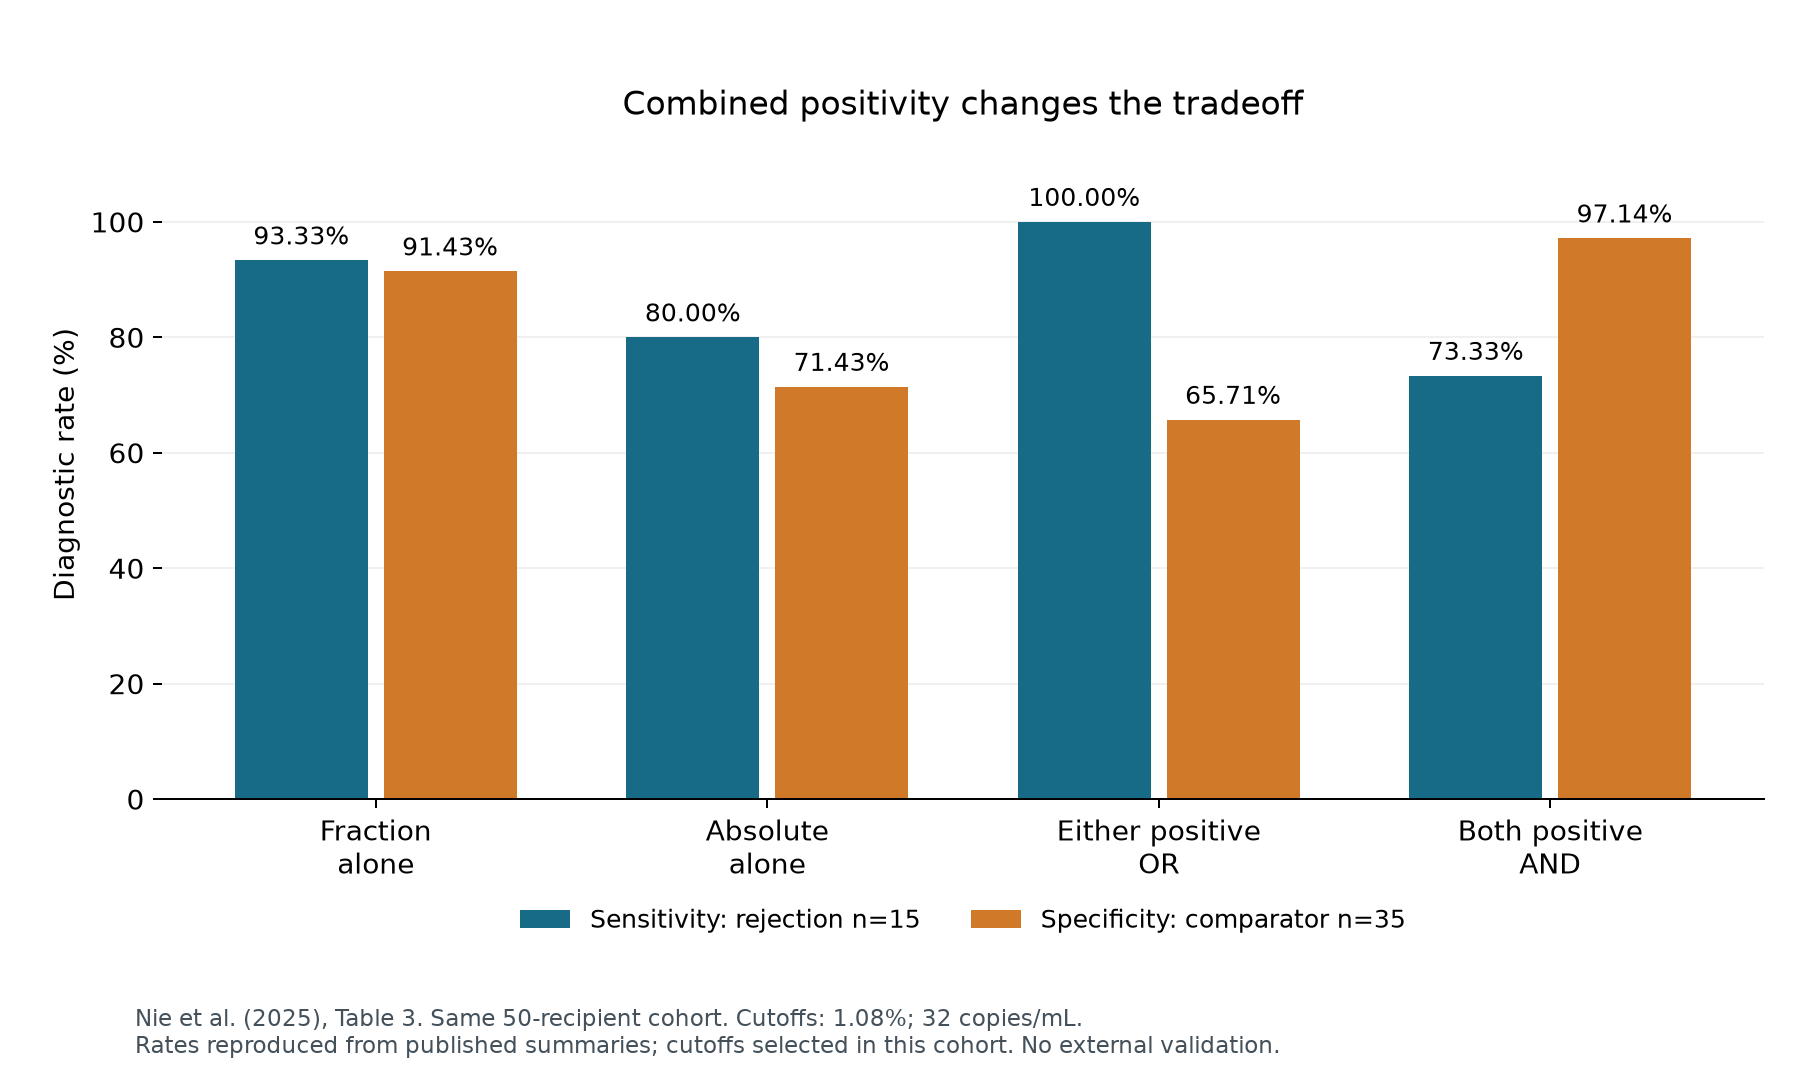

In [5]:
display(Image(filename=str(ROOT / 'figures/01_diagnostic_performance.png')))

## 5. Translate rates into errors

**Figure 2:** reconstructed false negatives and false positives in the same cohort. Panel denominators and vertical scales differ. These counts do not assign equal clinical costs to the two errors.

**Inspect:** relative to fraction alone, count the additional missed rejections and avoided false positives under AND. Why does observed OR sensitivity of 15/15 not establish that biopsy can safely be replaced?

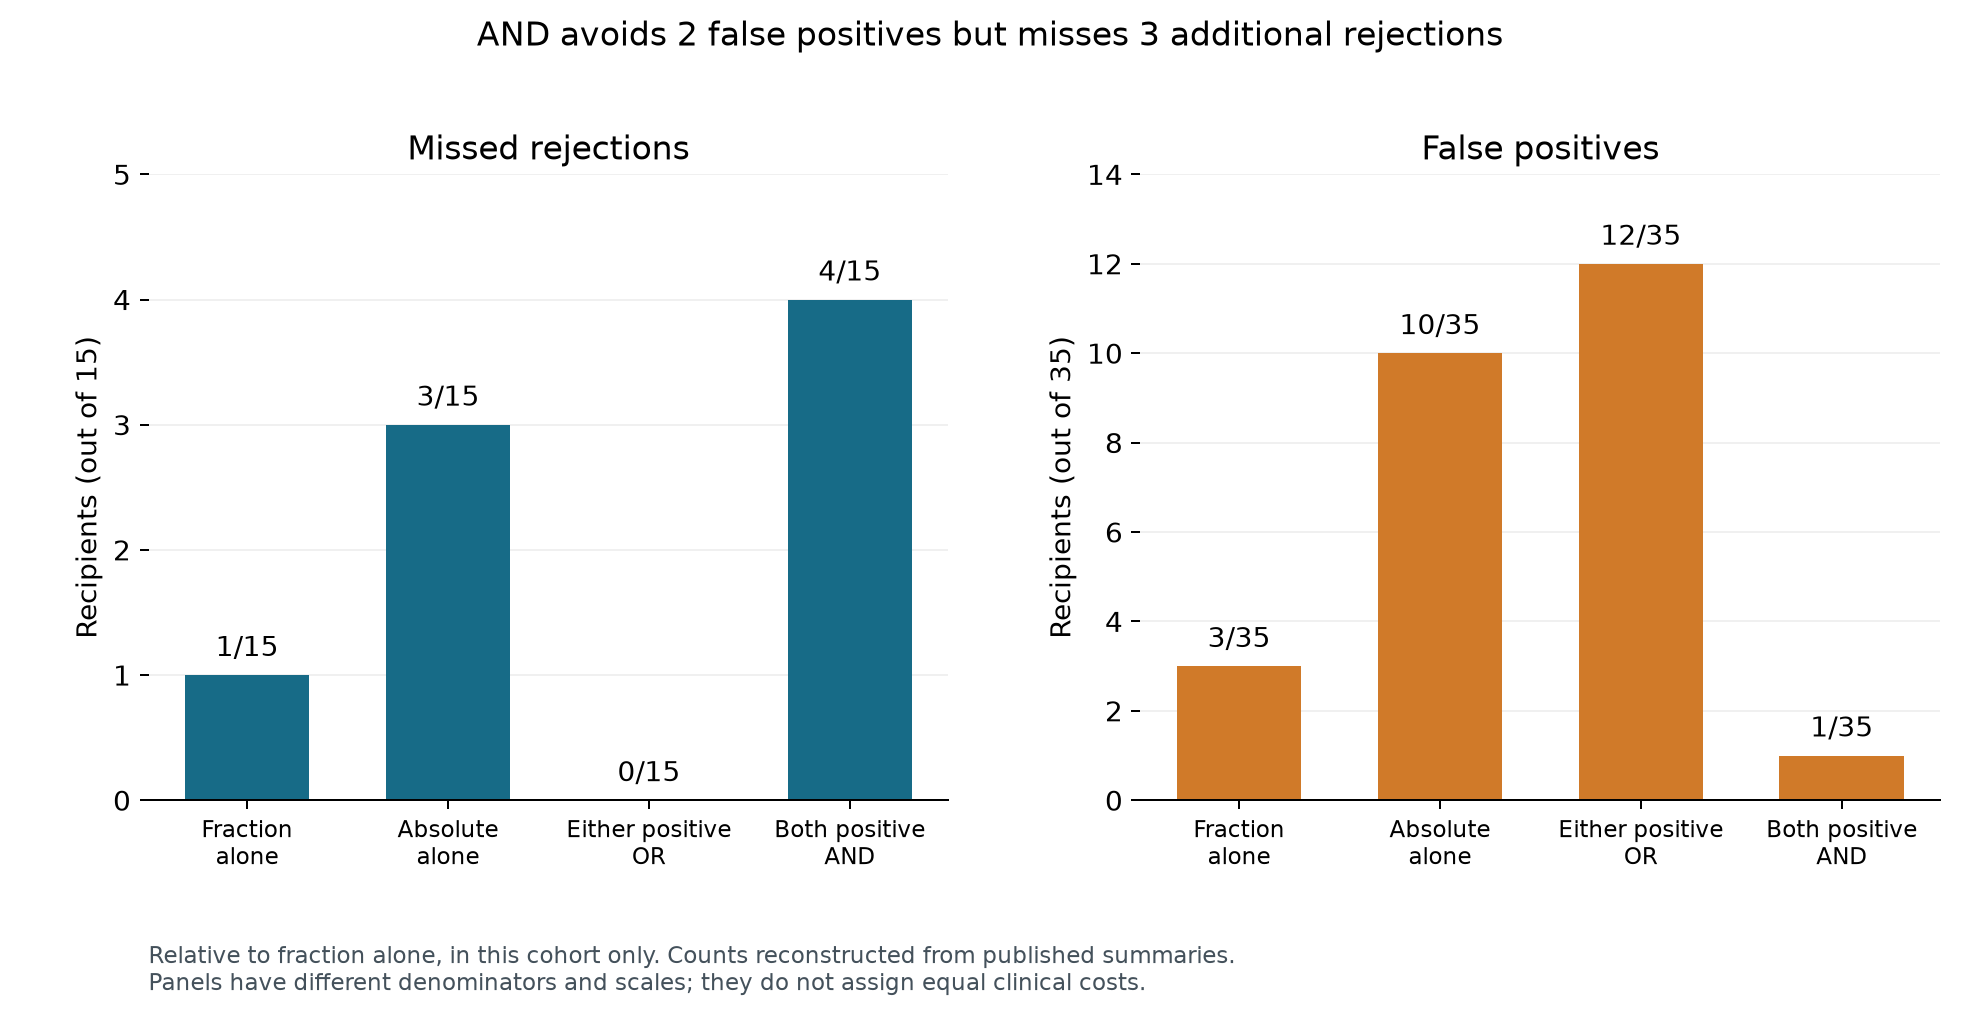

In [6]:
display(Image(filename=str(ROOT / 'figures/02_diagnostic_errors.png')))

## 6. Biological interpretation and proposed next study

In the 50-recipient biopsy cohort reported by Nie et al., requiring both fractional and absolute dd-cfDNA positivity reduced false positives from 3/35 to 1/35 compared with fraction alone, but increased missed rejections from 1/15 to 4/15. Either-positive classification detected all 15 observed rejection cases, with 12/35 false positives. These reconstructed counts show that a higher positive predictive value can accompany lower sensitivity; they do not establish a universally preferable rule.

Biologically, donor fraction depends on both donor-derived and total cfDNA. Recipient cfDNA variation can change the fraction without a proportional change in donor concentration. However, this study calculated absolute dd-cfDNA by multiplying total cfDNA by donor fraction, so the quantities are mathematically coupled. Assay calibration, preanalytical variation, non-rejection injury, and phenotype composition offer competing explanations for discordance; the summary data cannot identify a mechanism.

Fourteen of fifteen rejection recipients had ABMR/mixed rejection, only one had TCMR, and borderline TCMR was classified as a comparator. Cutoffs were optimized within the same cohort. Thus observed 100% sensitivity or NPV has limited precision and does not justify replacing biopsy. PPV and NPV also depend on prevalence. The proposed next study is independent validation of prespecified rules, standardized assays and collection, adequate rejection-phenotype representation, blinded reference assessment, and explicit handling of repeated samples. This proposal has not been conducted.

Source: [Nie et al. (2025), Tables 1–3 and methods](https://pmc.ncbi.nlm.nih.gov/articles/PMC11817499/).

## 7. Evidence and reuse

The analysis makes diagnostic tradeoffs explicit and checks their numerical consistency. Generalization requires independent validation of prespecified rules in a suitable clinical cohort.

Source tables and derived summaries are attributed to [Nie et al. (2025)](https://pmc.ncbi.nlm.nih.gov/articles/PMC11817499/) under CC BY 4.0. Original project code is MIT-licensed.

The final cell creates a downloadable archive of regenerated figures, processed summaries, source inputs, and analysis code.


In [7]:
import zipfile
zip_path = ROOT / 'regenerated-analysis.zip'
with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for folder in ['figures', 'data/published_summary', 'data/processed']:
        for path in sorted((ROOT / folder).glob('*')):
            if path.is_file():
                archive.write(path, path.relative_to(ROOT).as_posix())
    for relative in ['run_analysis.py', 'INPUT_MANIFEST.json', 'data/SOURCES.md', 'NOTICE.md', 'LICENSE']:
        archive.write(ROOT / relative, relative)
print('Regenerated analysis ZIP created. Save the executed notebook separately.')
try:
    from google.colab import files
except ImportError:
    print('Open the notebook runtime file browser to download:', zip_path.relative_to(Path.cwd()).as_posix())
else:
    files.download(str(zip_path))

Regenerated analysis ZIP created. Save the executed notebook separately.
Open the notebook runtime file browser to download: kidney-ddcfdna-analysis/regenerated-analysis.zip
